<a href="https://colab.research.google.com/github/hab5510/finrl_project/blob/main/with_sentiment_optimized/FinRL_with_SentimentAnalysis_optimized.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Deep Reinforcement Learning for Stock Trading, Multiple Stock Trading with Optimized Sentiment Analysis




# Content

1. **Task Description**
2. **Install & Import Packages**
3. **Download and Preprocess Data**
4. **Sentiment Analysis**
   - Financial News Dataset (FNSPID)
   - FinBERT Classification
   - Feature Engineering (Optimized Sentiment)
5. **Build Trading Environment**
   - Environment Setup
   - Data Split
6. **Training the Agents**
   - A2C
   - PPO
   - TD3
7. **Out-of-sample Trading**
8. **Evaluation and Results**
   - Portfolio Values
   - Cumulative Return and Sharpe Ratio

<a id='0'></a>
# Part 1. Task Discription

This notebook explores whether optimized sentiment features can enhance the performance of reinforcement learning agents in stock trading.

We extract daily financial news headlines from the FNSPID dataset and use FinBERT — a finance-specific BERT model — to classify each headline as positive, neutral, or negative.

The resulting sentiment scores are:
- Aggregated daily per stock
- Smoothed using Exponential Moving Average (EMA)
- Normalized to control for extreme values

These optimized sentiment features are integrated into the FinRL trading environment.  
Three DRL agents — A2C, PPO, and TD3 — are trained and tested on market data from 2020 to 2023.  
Performance is evaluated using final portfolio value, cumulative return, and Sharpe ratio, compared to a Dow Jones baseline.


<a id='1'></a>
# Part 2. Install & Import Packages

<a id='1.1'></a>
### Install packages


In [1]:
# [Patched for local run] Skipped: this environment (Python 3.13, macOS arm64) already
# has mutually-compatible versions of these packages pre-installed. The notebook's original
# pinned versions (numpy==1.26.4, torch==2.2.2, stable-baselines3==2.2.1, transformers==4.41.0)
# predate Python 3.13 and have no wheels for it -- reinstalling them here would break the
# working environment. See installed versions below.
import numpy, torch, stable_baselines3, gymnasium
print('numpy', numpy.__version__, '| torch', torch.__version__, '| sb3', stable_baselines3.__version__, '| gymnasium', gymnasium.__version__)


numpy 2.5.1 | torch 2.13.0 | sb3 2.9.0 | gymnasium 0.29.1


In [2]:
# [Patched for local run] Skipped: this environment (Python 3.13, macOS arm64) already
# has mutually-compatible versions of these packages pre-installed. The notebook's original
# pinned versions (numpy==1.26.4, torch==2.2.2, stable-baselines3==2.2.1, transformers==4.41.0)
# predate Python 3.13 and have no wheels for it -- reinstalling them here would break the
# working environment. See installed versions below.
import numpy, torch, stable_baselines3, gymnasium
print('numpy', numpy.__version__, '| torch', torch.__version__, '| sb3', stable_baselines3.__version__, '| gymnasium', gymnasium.__version__)


numpy 2.5.1 | torch 2.13.0 | sb3 2.9.0 | gymnasium 0.29.1


<a id='1.3'></a>
### Import Packages

In [3]:
!pip install pandas_market_calendars

In [4]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
# matplotlib.use('Agg')
import datetime

%matplotlib inline
from finrl.meta.preprocessor.yahoodownloader import YahooDownloader
from finrl.meta.preprocessor.preprocessors import FeatureEngineer, data_split
from finrl.meta.env_stock_trading.env_stocktrading import StockTradingEnv
from finrl.agents.stablebaselines3.models import DRLAgent
from stable_baselines3.common.logger import configure
from finrl.meta.data_processor import DataProcessor

from finrl.plot import backtest_stats, backtest_plot, get_daily_return, get_baseline
from pprint import pprint

import sys
sys.path.append("../FinRL")

import itertools

/Users/vijay/Desktop/sentiment-drl-trading/.venv/lib/python3.13/site-packages/pyfolio/pos.py:25: UserWarning: Module "zipline.assets" not found; multipliers will not be applied to position notionals.
  warnings.warn(


<a id='1.4'></a>
### Create Folders

In [5]:
from finrl import config
from finrl import config_tickers
import os
from finrl.main import check_and_make_directories
from finrl.config import (
    DATA_SAVE_DIR,
    TRAINED_MODEL_DIR,
    TENSORBOARD_LOG_DIR,
    RESULTS_DIR,
    INDICATORS,
    TRAIN_START_DATE,
    TRAIN_END_DATE,
    TEST_START_DATE,
    TEST_END_DATE,
    TRADE_START_DATE,
    TRADE_END_DATE,
)
check_and_make_directories([DATA_SAVE_DIR, TRAINED_MODEL_DIR, TENSORBOARD_LOG_DIR, RESULTS_DIR])



In [6]:
# (Kaggle: no Drive mount needed -- FNSPID is streamed from Hugging Face below instead.)


<a id='2'></a>
# Part 3. Download and Preprocess Data

The data for this case study is obtained from Yahoo Finance API. The data contains Open-High-Low-Close price and volume.
Yahoo Finance provides stock data, financial news, financial reports, etc. Yahoo Finance is free.
* FinRL uses a class **YahooDownloader** in FinRL-Meta to fetch data via Yahoo Finance API
* Call Limit: Using the Public API (without authentication), you are limited to 2,000 requests per hour per IP (or up to a total of 48,000 requests a day).

We are using 10 of the top 10 Tickers in the market : AAPL, MSFT, AMZN, GOOGL, META,
                 NVDA, JPM, TSLA, BA, DIS



-----
class YahooDownloader:
    Retrieving daily stock data from
    Yahoo Finance API

    Attributes
    ----------
        start_date : str
            start date of the data (modified from config.py)
        end_date : str
            end date of the data (modified from config.py)
        ticker_list : list
            a list of stock tickers (modified from config.py)

    Methods
    -------
    fetch_data()


In [7]:
TRAIN_START_DATE = '2020-01-01'
TRAIN_END_DATE = '2023-01-01'
TRADE_START_DATE = '2023-01-01'
TRADE_END_DATE = '2023-12-31'


In [8]:
top10_tickers = ['AAPL','MSFT','AMZN','GOOGL','META',
                 'NVDA','JPM','TSLA','BA','DIS']

df = YahooDownloader(start_date = TRAIN_START_DATE,
                     end_date = TRADE_END_DATE,
                     ticker_list = top10_tickers).fetch_data()

YF deprecation warning: set proxy via new config function: yf.set_config(proxy=proxy)


[*********************100%***********************]  1 of 1 completed

[*********************100%***********************]  1 of 1 completed

[*********************100%***********************]  1 of 1 completed

[*********************100%***********************]  1 of 1 completed

...

[*********************100%***********************]  1 of 1 completed

[*********************100%***********************]  1 of 1 completed

[*********************100%***********************]  1 of 1 completed

[*********************100%***********************]  1 of 1 completed

Shape of DataFrame:  (10060, 8)


In [9]:
df.shape

(10060, 8)

In [10]:
df.sort_values(['date','tic'],ignore_index=True).head()

Price,date,close,high,low,open,volume,tic,day
0,2020-01-02,72.333870,72.394078,71.091176,71.344047,135480400,AAPL,3
1,2020-01-02,94.900497,94.900497,93.207497,93.750000,80580000,AMZN,3
2,2020-01-02,331.348572,331.378393,325.761816,326.606765,4544400,BA,3
3,2020-01-02,143.689270,143.689270,140.683633,140.867837,9502100,DIS,3
4,2020-01-02,67.832512,67.832512,66.732767,66.827923,27278000,GOOGL,3


### Preprocess Data
We need to check for missing data and do feature engineering to convert the data point into a state.
* **Adding technical indicators**. In practical trading, various information needs to be taken into account, such as historical prices, current holding shares, technical indicators, etc. Here, we demonstrate two trend-following technical indicators: MACD and RSI.
* **Adding turbulence index**. Risk-aversion reflects whether an investor prefers to protect the capital. It also influences one's trading strategy when facing different market volatility level. To control the risk in a worst-case scenario, such as financial crisis of 2007–2008, FinRL employs the turbulence index that measures extreme fluctuation of asset price.

In [11]:
fe = FeatureEngineer(
                    use_technical_indicator=True,
                    tech_indicator_list = INDICATORS,
                    use_vix=True,
                    use_turbulence=True,
                    user_defined_feature = False)

processed = fe.preprocess_data(df)


Successfully added technical indicators


[*********************100%***********************]  1 of 1 completed

Shape of DataFrame:  (1005, 8)
Successfully added vix


Successfully added turbulence index


# Part 4. Sentiment Analysis



### Financial News Dataset: FNSPID

We use the FNSPID dataset, which contains 15.7M financial news headlines labeled with stock tickers and publication time.

In this notebook, headlines are processed using FinBERT to compute daily sentiment scores for each stock.

It is available at https://huggingface.co/datasets/Zihan1004/FNSPID  . It was directly downloaded as csv and uploaded below.


In [12]:
# [Patched for local run] Skipped: sentiment scoring already computed and cached in
# processed_full_*.csv in this folder. Recomputing it here would require streaming the
# ~30GB FNSPID dataset and downloading/running a 3B-parameter Qwen LLM behind a private,
# gated HF adapter repo -- infeasible for a routine local re-run. The cached CSV is read
# directly in Part 5 below.


In [13]:
# [Patched for local run] skipped -- see note above.


### FinBERT Classification

Classifies each headline as positive, neutral, or negative using a finance-specific BERT model.

In [14]:
# [Patched for local run] skipped -- see note above.


In [15]:
# [Patched for local run] skipped -- see note above.


In [16]:
# [Patched for local run] skipped -- see note above.


In [17]:
# [Patched for local run] skipped -- see note above.


In [18]:
# [Patched for local run] skipped -- see note above.


In [19]:
# [Patched for local run] skipped -- see note above.



### Feature Engineering: Optimized Sentiment

After classifying each headline using FinBERT, we compute a **daily average sentiment score per stock**.

To reduce noise and improve input stability, we apply two key preprocessing steps:

1. **EMA Smoothing (Exponential Moving Average)**  
   We smooth sentiment values using EMA with `span=3`,  
   which means recent values are weighted more heavily, with a memory of the last 3 days.  
   This helps the agent detect short-term sentiment trends without overreacting to sudden news spikes.

2. **Normalization (StandardScaler)**  
   The smoothed scores are scaled to have zero mean and unit variance.  
   This ensures comparability across different stocks and time periods.

The resulting **optimized sentiment score** is added to the RL agent’s observation space alongside market indicators.



In [20]:
# [Patched for local run] skipped -- see note above.


In [21]:
# [Patched for local run] skipped -- see note above.


In [22]:
# [Patched for local run] skipped -- see note above.


<a id='4'></a>
# Part 5. Build Trading Environment

#### Environment Setup

We use FinRL's `StockTradingEnv`, modified to include:
- Price-based technical indicators
- Sentiment features (raw, optimized, volatility)

#### Data Split
- **Training**: Jan 2020 – Dec 2022
- **Testing**: Jan 2023 – Dec 2023


In [23]:
INDICATORS = [
    'macd', 'boll_ub', 'boll_lb', 'rsi_30', 'cci_30', 'dx_30',
    'close_30_sma', 'close_60_sma', 'sentiment_score','vix', 'turbulence'
]

In [24]:
# Keep only the valid columns

VALID_COLUMNS = ['date', 'tic', 'open', 'high', 'low', 'close', 'volume','day'] + INDICATORS
processed_full = pd.read_csv("processed_full_smoothing_scaling.csv")
processed_full = processed_full[VALID_COLUMNS]
processed_full.dropna(inplace=True)

In [25]:
processed_full.sort_values(['date','tic'],ignore_index=True).head(20)

,date,tic,open,high,low,close,volume,day,macd,boll_ub,boll_lb,rsi_30,cci_30,dx_30,close_30_sma,close_60_sma,sentiment_score,vix,turbulence
0,2020-01-02,AAPL,71.627092,72.681289,71.373218,72.620842,135480400.0,3.0,0.000000,73.266313,71.269332,0.0,-66.666667,100.0,72.620842,72.620842,0.000000,12.47,0.0
1,2020-01-02,AMZN,93.750000,94.900497,93.207497,94.900497,80580000.0,3.0,0.000000,73.266313,71.269332,0.0,-66.666667,100.0,94.900497,94.900497,0.000000,12.47,0.0
2,2020-01-02,BA,326.606765,331.378393,325.761816,331.348572,4544400.0,3.0,0.000000,73.266313,71.269332,0.0,-66.666667,100.0,331.348572,331.348572,-2.783217,12.47,0.0
3,2020-01-02,DIS,142.907610,145.769897,142.720739,145.769897,9502100.0,3.0,0.000000,73.266313,71.269332,0.0,-66.666667,100.0,145.769897,145.769897,0.148809,12.47,0.0
4,2020-01-02,GOOGL,67.018569,68.026024,66.923141,68.026024,27278000.0,3.0,0.000000,73.266313,71.269332,0.0,-66.666667,100.0,68.026024,68.026024,-1.154314,12.47,0.0
5,2020-01-02,JPM,119.621142,120.742147,119.167612,120.733582,10803700.0,3.0,0.000000,73.266313,71.269332,0.0,-66.666667,100.0,120.733582,120.733582,0.881815,12.47,0.0
6,2020-01-02,META,205.621925,208.645331,205.144548,208.635391,12077100.0,3.0,0.000000,73.266313,71.269332,0.0,-66.666667,100.0,208.635391,208.635391,0.000000,12.47,0.0
7,2020-01-02,MSFT,151.289078,153.147078,150.860311,153.042267,22622100.0,3.0,0.000000,73.266313,71.269332,0.0,-66.666667,100.0,153.042267,153.042267,0.000000,12.47,0.0
8,2020-01-02,NVDA,5.942872,5.971746,5.892342,5.971746,237536000.0,3.0,0.000000,73.266313,71.269332,0.0,-66.666667,100.0,5.971746,5.971746,0.000000,12.47,0.0
9,2020-01-02,TSLA,28.299999,28.713333,28.114000,28.684000,142981500.0,3.0,0.000000,73.266313,71.269332,0.0,-66.666667,100.0,28.684000,28.684000,-0.339862,12.47,0.0


In [26]:
train = data_split(processed_full, TRAIN_START_DATE,TRAIN_END_DATE)
trade = data_split(processed_full, TRADE_START_DATE,TRADE_END_DATE)
print(len(train))
print(len(trade))

7560
2490


In [27]:
train.tail()

,date,tic,open,high,low,close,volume,day,macd,boll_ub,boll_lb,rsi_30,cci_30,dx_30,close_30_sma,close_60_sma,sentiment_score,vix,turbulence
755,2022-12-30,JPM,124.543618,125.969014,124.196653,125.753334,9292500.0,4.0,0.423460,126.849698,120.917208,57.144008,20.441546,11.345611,124.882475,119.589299,0.000000,21.67,0.766232
755,2022-12-30,META,117.515312,119.762976,117.097598,119.683411,19583800.0,4.0,0.952231,122.984851,111.411236,49.419036,78.427354,9.186676,115.435049,115.697442,0.000000,21.67,0.766232
755,2022-12-30,MSFT,233.466236,235.181386,231.947100,235.044174,21938500.0,4.0,-1.366761,253.270823,227.343633,48.258158,-86.505070,5.313343,240.472864,234.587169,0.526060,21.67,0.766232
755,2022-12-30,NVDA,14.321270,14.616008,14.220360,14.601022,310490000.0,4.0,-0.309794,18.503088,13.800796,47.045446,-141.558902,13.239284,16.120590,14.735053,1.212132,21.67,0.766232
755,2022-12-30,TSLA,119.949997,124.480003,119.750000,123.180000,157777300.0,4.0,-19.258998,202.513339,99.254662,32.790586,-121.998583,47.953532,161.267667,186.598834,0.698712,21.67,0.766232


In [28]:
trade.head()

,date,tic,open,high,low,close,volume,day,macd,boll_ub,boll_lb,rsi_30,cci_30,dx_30,close_30_sma,close_60_sma,sentiment_score,vix,turbulence
0,2023-01-03,AAPL,128.613993,129.226060,122.582127,123.470619,112117500.0,1.0,-4.648596,147.860264,121.091861,39.011483,-130.963709,35.956223,138.293939,140.567288,-0.0803,22.9,29.954573
0,2023-01-03,AMZN,85.459999,86.959999,84.209999,85.820000,76706000.0,1.0,-3.075118,93.357149,80.929850,41.195599,-71.360174,10.198927,89.424999,97.181000,0.0000,22.9,29.954573
0,2023-01-03,BA,192.949997,197.179993,192.399994,195.389999,8624600.0,1.0,5.326285,196.702727,176.154272,62.905353,141.206999,44.456630,182.859667,166.269167,0.0000,22.9,29.954573
0,2023-01-03,DIS,87.520962,88.494726,86.389817,87.511124,14997100.0,1.0,-2.395932,95.452681,81.433499,44.489007,-57.420733,3.756705,90.752426,93.693726,1.0905,22.9,29.954573
0,2023-01-03,GOOGL,89.055899,90.507201,87.992278,88.588707,28131200.0,1.0,-2.129974,98.089503,83.452726,43.976959,-67.730775,2.932399,92.974733,93.988818,0.0000,22.9,29.954573


In [29]:
stock_dimension = len(train.tic.unique())
state_space = 1 + 2*stock_dimension + len(INDICATORS)*stock_dimension
print(f"Stock Dimension: {stock_dimension}, State Space: {state_space}")

Stock Dimension: 10, State Space: 131


In [30]:

from finrl.meta.env_stock_trading.env_stocktrading import StockTradingEnv
import numpy as np

EXPECTED_STATE_DIM = state_space

def force_fixed_state(obs):
    obs = np.asarray(obs, dtype=np.float32).flatten()
    if obs.shape[0] != EXPECTED_STATE_DIM:
        print(f"Auto-fixing bad obs shape {obs.shape[0]} → {EXPECTED_STATE_DIM}")
        if obs.shape[0] < EXPECTED_STATE_DIM:
            # Pad with zeros
            obs = np.pad(obs, (0, EXPECTED_STATE_DIM - obs.shape[0]), mode='constant')
        else:
            # Truncate
            obs = obs[:EXPECTED_STATE_DIM]
    return obs.reshape(1, -1)


class PatchedStockTradingEnv(StockTradingEnv):
    def reset(self, *, seed=None, options=None):
        obs, info = super().reset(seed=seed, options=options)
        obs = force_fixed_state(obs)
        return obs, info

    def step(self, action):
        obs, reward, terminated, truncated, info = super().step(action)
        obs = force_fixed_state(obs)
        return obs, reward, terminated, truncated, info








In [31]:
buy_cost_list = sell_cost_list = [0.001] * stock_dimension
num_stock_shares = [0] * stock_dimension

env_kwargs = {
    "hmax": 100,
    "initial_amount": 1000000,
    "num_stock_shares": num_stock_shares,
    "buy_cost_pct": buy_cost_list,
    "sell_cost_pct": sell_cost_list,
    "state_space": state_space,
    "stock_dim": stock_dimension,
    "tech_indicator_list": INDICATORS,
    "action_space": stock_dimension,
    "reward_scaling": 1e-4
}

from stable_baselines3.common.vec_env import DummyVecEnv

env_train = DummyVecEnv([lambda: PatchedStockTradingEnv(df=train, **env_kwargs)])






In [32]:
# [Patched for local run] Skipped: this debug/demo cell calls env_train.step() with a
# malformed action shape for a vectorized DummyVecEnv (works with 1 stock, breaks with
# more). Under numpy 1.x this silently coerced via a 0-d-array nonzero call; numpy 2.x
# raises 'Calling nonzero on 0d arrays is not allowed'. Not used by training below.


In [33]:
# [Patched for local run] skipped -- see note above.


<a id='5'></a>

# Part 6. Training the Agents (A2C, PPO, TD3)

Each model is trained independently on the same market + sentiment environment.
Training duration varies (TD3 longer than others).


### Agent 1: A2C


In [34]:
agent = DRLAgent(env = env_train)
model_a2c = agent.get_model("a2c")


# set up logger
tmp_path = RESULTS_DIR + '/a2c'
new_logger_a2c = configure(tmp_path, ["stdout", "csv", "tensorboard"])
# Set new logger
model_a2c.set_logger(new_logger_a2c)


{'n_steps': 5, 'ent_coef': 0.01, 'learning_rate': 0.0007}
Using cpu device


Logging to results/a2c


In [35]:
print(repr(env_train.reset()))

array([[ 1.0000000e+06,  7.2620842e+01,  9.4900497e+01,  3.3134857e+02,
         1.4576990e+02,  6.8026024e+01,  1.2073358e+02,  2.0863539e+02,
         1.5304227e+02,  5.9717460e+00,  2.8684000e+01,  0.0000000e+00,
         0.0000000e+00,  0.0000000e+00,  0.0000000e+00,  0.0000000e+00,
         0.0000000e+00,  0.0000000e+00,  0.0000000e+00,  0.0000000e+00,
         0.0000000e+00,  0.0000000e+00,  0.0000000e+00,  0.0000000e+00,
         0.0000000e+00,  0.0000000e+00,  0.0000000e+00,  0.0000000e+00,
         0.0000000e+00,  0.0000000e+00,  0.0000000e+00,  7.3266312e+01,
         7.3266312e+01,  7.3266312e+01,  7.3266312e+01,  7.3266312e+01,
         7.3266312e+01,  7.3266312e+01,  7.3266312e+01,  7.3266312e+01,
         7.3266312e+01,  7.1269333e+01,  7.1269333e+01,  7.1269333e+01,
         7.1269333e+01,  7.1269333e+01,  7.1269333e+01,  7.1269333e+01,
         7.1269333e+01,  7.1269333e+01,  7.1269333e+01,  0.0000000e+00,
         0.0000000e+00,  0.0000000e+00,  0.0000000e+00,  0.00000

In [36]:
trained_a2c  = agent.train_model(model=model_a2c,
                             tb_log_name='a2c',
                             total_timesteps=50000)

-------------------------------------
| time/                 |           |
|    fps                | 1140      |
|    iterations         | 100       |
|    time_elapsed       | 0         |
|    total_timesteps    | 500       |
| train/                |           |
|    entropy_loss       | -14.1     |
|    explained_variance | 0.003     |
|    learning_rate      | 0.0007    |
|    n_updates          | 99        |
|    policy_loss        | -43.2     |
|    reward             | 0.9308702 |
|    reward_max         | 4.3800335 |
|    reward_mean        | 1.5480024 |
|    reward_min         | -3.024598 |
|    std                | 0.996     |
|    value_loss         | 11.6      |
-------------------------------------


----------------------------------------
| time/                 |              |
|    fps                | 1225         |
|    iterations         | 200          |
|    time_elapsed       | 0            |
|    total_timesteps    | 1000         |
| train/                |              |
|    entropy_loss       | -14.2        |
|    explained_variance | -0.126       |
|    learning_rate      | 0.0007       |
|    n_updates          | 199          |
|    policy_loss        | -22.7        |
|    reward             | 0.2342453    |
|    reward_max         | 0.44038495   |
|    reward_mean        | 0.0074166716 |
|    reward_min         | -0.5934233   |
|    std                | 0.999        |
|    value_loss         | 3.87         |
----------------------------------------


----------------------------------------
| time/                 |              |
|    fps                | 1252         |
|    iterations         | 300          |
|    time_elapsed       | 1            |
|    total_timesteps    | 1500         |
| train/                |              |
|    entropy_loss       | -14.2        |
|    explained_variance | -0.167       |
|    learning_rate      | 0.0007       |
|    n_updates          | 299          |
|    policy_loss        | -32.4        |
|    reward             | 0.03423331   |
|    reward_max         | 0.93030584   |
|    reward_mean        | 0.4966584    |
|    reward_min         | -0.086117685 |
|    std                | 0.997        |
|    value_loss         | 6.18         |
----------------------------------------


-------------------------------------
| time/                 |           |
|    fps                | 1265      |
|    iterations         | 400       |
|    time_elapsed       | 1         |
|    total_timesteps    | 2000      |
| train/                |           |
|    entropy_loss       | -14.1     |
|    explained_variance | -0.129    |
|    learning_rate      | 0.0007    |
|    n_updates          | 399       |
|    policy_loss        | -65.3     |
|    reward             | 1.0121796 |
|    reward_max         | 2.6294227 |
|    reward_mean        | 1.0770504 |
|    reward_min         | -2.219452 |
|    std                | 0.995     |
|    value_loss         | 26.8      |
-------------------------------------


-------------------------------------
| time/                 |           |
|    fps                | 1277      |
|    iterations         | 500       |
|    time_elapsed       | 1         |
|    total_timesteps    | 2500      |
| train/                |           |
|    entropy_loss       | -14.2     |
|    explained_variance | 0.401     |
|    learning_rate      | 0.0007    |
|    n_updates          | 499       |
|    policy_loss        | 39.6      |
|    reward             | 0.85525   |
|    reward_max         | 2.0585403 |
|    reward_mean        | 0.3257947 |
|    reward_min         | -1.815394 |
|    std                | 0.999     |
|    value_loss         | 7.54      |
-------------------------------------


...

--------------------------------------
| time/                 |            |
|    fps                | 1280       |
|    iterations         | 9600       |
|    time_elapsed       | 37         |
|    total_timesteps    | 48000      |
| train/                |            |
|    entropy_loss       | -14.5      |
|    explained_variance | -0.0223    |
|    learning_rate      | 0.0007     |
|    n_updates          | 9599       |
|    policy_loss        | -20.8      |
|    reward             | 1.0938574  |
|    reward_max         | 1.0938574  |
|    reward_mean        | 0.30560738 |
|    reward_min         | -2.0149944 |
|    std                | 1.04       |
|    value_loss         | 2.43       |
--------------------------------------


---------------------------------------
| time/                 |             |
|    fps                | 1280        |
|    iterations         | 9700        |
|    time_elapsed       | 37          |
|    total_timesteps    | 48500       |
| train/                |             |
|    entropy_loss       | -14.6       |
|    explained_variance | -0.0776     |
|    learning_rate      | 0.0007      |
|    n_updates          | 9699        |
|    policy_loss        | -71.3       |
|    reward             | 0.26108187  |
|    reward_max         | 1.5966703   |
|    reward_mean        | 0.87700856  |
|    reward_min         | -0.27713564 |
|    std                | 1.04        |
|    value_loss         | 26          |
---------------------------------------


---------------------------------------
| time/                 |             |
|    fps                | 1281        |
|    iterations         | 9800        |
|    time_elapsed       | 38          |
|    total_timesteps    | 49000       |
| train/                |             |
|    entropy_loss       | -14.6       |
|    explained_variance | 0           |
|    learning_rate      | 0.0007      |
|    n_updates          | 9799        |
|    policy_loss        | 0.437       |
|    reward             | -4.406717   |
|    reward_max         | 0.044886973 |
|    reward_mean        | -2.6650386  |
|    reward_min         | -4.552639   |
|    std                | 1.04        |
|    value_loss         | 1.38        |
---------------------------------------


--------------------------------------
| time/                 |            |
|    fps                | 1281       |
|    iterations         | 9900       |
|    time_elapsed       | 38         |
|    total_timesteps    | 49500      |
| train/                |            |
|    entropy_loss       | -14.6      |
|    explained_variance | 5.96e-08   |
|    learning_rate      | 0.0007     |
|    n_updates          | 9899       |
|    policy_loss        | 7.48       |
|    reward             | -0.4529273 |
|    reward_max         | 1.2625163  |
|    reward_mean        | 0.13435681 |
|    reward_min         | -1.0825517 |
|    std                | 1.04       |
|    value_loss         | 1          |
--------------------------------------


-----------------------------------------
| time/                 |               |
|    fps                | 1281          |
|    iterations         | 10000         |
|    time_elapsed       | 39            |
|    total_timesteps    | 50000         |
| train/                |               |
|    entropy_loss       | -14.6         |
|    explained_variance | 1.25e-06      |
|    learning_rate      | 0.0007        |
|    n_updates          | 9999          |
|    policy_loss        | 35.4          |
|    reward             | 0.24101159    |
|    reward_max         | 2.110049      |
|    reward_mean        | -0.0125410855 |
|    reward_min         | -1.9664555    |
|    std                | 1.04          |
|    value_loss         | 11.5          |
-----------------------------------------


### Agent 2: PPO

In [37]:
agent = DRLAgent(env = env_train)
PPO_PARAMS = {
    "n_steps": 2048,
    "ent_coef": 0.01,
    "learning_rate": 0.00025,
    "batch_size": 128,
}
model_ppo = agent.get_model("ppo",model_kwargs = PPO_PARAMS)

  # set up logger
tmp_path = RESULTS_DIR + '/ppo'
new_logger_ppo = configure(tmp_path, ["stdout", "csv", "tensorboard"])
  # Set new logger
model_ppo.set_logger(new_logger_ppo)

{'n_steps': 2048, 'ent_coef': 0.01, 'learning_rate': 0.00025, 'batch_size': 128}
Using cpu device
Logging to results/ppo


In [38]:
trained_ppo = agent.train_model(model=model_ppo,
                             tb_log_name='ppo',
                             total_timesteps=50000)

day: 755, episode: 70
begin_total_asset: 1000000.00
end_total_asset: 969087.02
total_reward: -30912.98
total_cost: 63393.36
total_trades: 7157
Sharpe: 0.129


------------------------------------
| time/              |             |
|    fps             | 1686        |
|    iterations      | 1           |
|    time_elapsed    | 1           |
|    total_timesteps | 2048        |
| train/             |             |
|    reward          | -0.09512135 |
|    reward_max      | 11.759163   |
|    reward_mean     | 0.019103894 |
|    reward_min      | -11.934808  |
------------------------------------


-----------------------------------------
| time/                   |             |
|    fps                  | 1589        |
|    iterations           | 2           |
|    time_elapsed         | 2           |
|    total_timesteps      | 4096        |
| train/                  |             |
|    approx_kl            | 0.008028234 |
|    clip_fraction        | 0.0792      |
|    clip_range           | 0.2         |
|    entropy_loss         | -14.2       |
|    explained_variance   | 0.00217     |
|    learning_rate        | 0.00025     |
|    loss                 | 22.7        |
|    n_updates            | 10          |
|    policy_gradient_loss | -0.0106     |
|    reward               | -0.5434513  |
|    reward_max           | 7.365951    |
|    reward_mean          | 0.015607184 |
|    reward_min           | -9.067837   |
|    std                  | 1           |
|    value_loss           | 37.2        |
-----------------------------------------


------------------------------------------
| time/                   |              |
|    fps                  | 1549         |
|    iterations           | 3            |
|    time_elapsed         | 3            |
|    total_timesteps      | 6144         |
| train/                  |              |
|    approx_kl            | 0.0070060715 |
|    clip_fraction        | 0.0906       |
|    clip_range           | 0.2          |
|    entropy_loss         | -14.2        |
|    explained_variance   | -0.00163     |
|    learning_rate        | 0.00025      |
|    loss                 | 15.5         |
|    n_updates            | 20           |
|    policy_gradient_loss | -0.00826     |
|    reward               | 1.1221203    |
|    reward_max           | 8.006127     |
|    reward_mean          | -0.033349764 |
|    reward_min           | -9.823287    |
|    std                  | 1            |
|    value_loss           | 27.6         |
------------------------------------------


------------------------------------------
| time/                   |              |
|    fps                  | 1542         |
|    iterations           | 4            |
|    time_elapsed         | 5            |
|    total_timesteps      | 8192         |
| train/                  |              |
|    approx_kl            | 0.0073331464 |
|    clip_fraction        | 0.0753       |
|    clip_range           | 0.2          |
|    entropy_loss         | -14.2        |
|    explained_variance   | 0.0422       |
|    learning_rate        | 0.00025      |
|    loss                 | 12.6         |
|    n_updates            | 30           |
|    policy_gradient_loss | -0.00979     |
|    reward               | 3.3131714    |
|    reward_max           | 9.226997     |
|    reward_mean          | 0.049245022  |
|    reward_min           | -9.551191    |
|    std                  | 1.01         |
|    value_loss           | 31.7         |
------------------------------------------


...

------------------------------------------
| time/                   |              |
|    fps                  | 1476         |
|    iterations           | 21           |
|    time_elapsed         | 29           |
|    total_timesteps      | 43008        |
| train/                  |              |
|    approx_kl            | 0.016638251  |
|    clip_fraction        | 0.172        |
|    clip_range           | 0.2          |
|    entropy_loss         | -14.4        |
|    explained_variance   | 0.0538       |
|    learning_rate        | 0.00025      |
|    loss                 | 13.9         |
|    n_updates            | 200          |
|    policy_gradient_loss | -0.0075      |
|    reward               | 0.20006093   |
|    reward_max           | 8.147656     |
|    reward_mean          | 0.0033920445 |
|    reward_min           | -8.972911    |
|    std                  | 1.02         |
|    value_loss           | 28.5         |
------------------------------------------


-----------------------------------------
| time/                   |             |
|    fps                  | 1478        |
|    iterations           | 22          |
|    time_elapsed         | 30          |
|    total_timesteps      | 45056       |
| train/                  |             |
|    approx_kl            | 0.012118341 |
|    clip_fraction        | 0.14        |
|    clip_range           | 0.2         |
|    entropy_loss         | -14.4       |
|    explained_variance   | 0.231       |
|    learning_rate        | 0.00025     |
|    loss                 | 10          |
|    n_updates            | 210         |
|    policy_gradient_loss | -0.00187    |
|    reward               | 1.698669    |
|    reward_max           | 8.902779    |
|    reward_mean          | 0.014109292 |
|    reward_min           | -8.040904   |
|    std                  | 1.02        |
|    value_loss           | 17.4        |
-----------------------------------------


day: 755, episode: 130
begin_total_asset: 1000000.00
end_total_asset: 1015386.63
total_reward: 15386.63
total_cost: 56894.78
total_trades: 6903
Sharpe: 0.138
-------------------------------------------
| time/                   |               |
|    fps                  | 1479          |
|    iterations           | 23            |
|    time_elapsed         | 31            |
|    total_timesteps      | 47104         |
| train/                  |               |
|    approx_kl            | 0.010736703   |
|    clip_fraction        | 0.13          |
|    clip_range           | 0.2           |
|    entropy_loss         | -14.4         |
|    explained_variance   | 0.317         |
|    learning_rate        | 0.00025       |
|    loss                 | 10.9          |
|    n_updates            | 220           |
|    policy_gradient_loss | -0.00876      |
|    reward               | 0.46238354    |
|    reward_max           | 8.348762      |
|    reward_mean          | -0.0031274343 |
|    r

------------------------------------------
| time/                   |              |
|    fps                  | 1475         |
|    iterations           | 24           |
|    time_elapsed         | 33           |
|    total_timesteps      | 49152        |
| train/                  |              |
|    approx_kl            | 0.012021909  |
|    clip_fraction        | 0.0794       |
|    clip_range           | 0.2          |
|    entropy_loss         | -14.4        |
|    explained_variance   | 0.321        |
|    learning_rate        | 0.00025      |
|    loss                 | 10.5         |
|    n_updates            | 230          |
|    policy_gradient_loss | -0.00722     |
|    reward               | 0.0029961215 |
|    reward_max           | 8.531252     |
|    reward_mean          | -0.004521715 |
|    reward_min           | -7.412112    |
|    std                  | 1.02         |
|    value_loss           | 21.5         |
------------------------------------------


-----------------------------------------
| time/                   |             |
|    fps                  | 1477        |
|    iterations           | 25          |
|    time_elapsed         | 34          |
|    total_timesteps      | 51200       |
| train/                  |             |
|    approx_kl            | 0.008396775 |
|    clip_fraction        | 0.0733      |
|    clip_range           | 0.2         |
|    entropy_loss         | -14.4       |
|    explained_variance   | 0.324       |
|    learning_rate        | 0.00025     |
|    loss                 | 8.46        |
|    n_updates            | 240         |
|    policy_gradient_loss | -0.00596    |
|    reward               | -5.96593    |
|    reward_max           | 8.928743    |
|    reward_mean          | 0.017296562 |
|    reward_min           | -7.5437913  |
|    std                  | 1.02        |
|    value_loss           | 20.4        |
-----------------------------------------


### Agent 3: TD3

In [39]:
agent = DRLAgent(env = env_train)
TD3_PARAMS = {"batch_size": 100,
              "buffer_size": 1000000,
              "learning_rate": 0.001}

model_td3 = agent.get_model("td3",model_kwargs = TD3_PARAMS)

  # set up logger
tmp_path = RESULTS_DIR + '/td3'
new_logger_td3 = configure(tmp_path, ["stdout", "csv", "tensorboard"])
  # Set new logger
model_td3.set_logger(new_logger_td3)

{'batch_size': 100, 'buffer_size': 1000000, 'learning_rate': 0.001}
Using cpu device
Logging to results/td3


In [40]:
trained_td3 = agent.train_model(model=model_td3,
                             tb_log_name='td3',
                             total_timesteps=50000)

Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging 

Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging 

Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'


Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'


Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging 

...

Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'


Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'


Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'


Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'


Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'


# Part 7. Out-of-Sample Trading

This section simulates live trading by deploying each trained agent on **unseen test data from 2023**.

Each agent starts with **$1,000,000** and trades across 10 U.S. stocks.  
Daily portfolio values are recorded to evaluate performance later.


In [41]:
e_trade_gym = StockTradingEnv(df = trade, turbulence_threshold = 70,risk_indicator_col='vix', **env_kwargs)

In [42]:
trade.head()

,date,tic,open,high,low,close,volume,day,macd,boll_ub,boll_lb,rsi_30,cci_30,dx_30,close_30_sma,close_60_sma,sentiment_score,vix,turbulence
0,2023-01-03,AAPL,128.613993,129.226060,122.582127,123.470619,112117500.0,1.0,-4.648596,147.860264,121.091861,39.011483,-130.963709,35.956223,138.293939,140.567288,-0.0803,22.9,29.954573
0,2023-01-03,AMZN,85.459999,86.959999,84.209999,85.820000,76706000.0,1.0,-3.075118,93.357149,80.929850,41.195599,-71.360174,10.198927,89.424999,97.181000,0.0000,22.9,29.954573
0,2023-01-03,BA,192.949997,197.179993,192.399994,195.389999,8624600.0,1.0,5.326285,196.702727,176.154272,62.905353,141.206999,44.456630,182.859667,166.269167,0.0000,22.9,29.954573
0,2023-01-03,DIS,87.520962,88.494726,86.389817,87.511124,14997100.0,1.0,-2.395932,95.452681,81.433499,44.489007,-57.420733,3.756705,90.752426,93.693726,1.0905,22.9,29.954573
0,2023-01-03,GOOGL,89.055899,90.507201,87.992278,88.588707,28131200.0,1.0,-2.129974,98.089503,83.452726,43.976959,-67.730775,2.932399,92.974733,93.988818,0.0000,22.9,29.954573


In [43]:
trained_moedl = trained_a2c
df_account_value_a2c, df_actions_a2c = DRLAgent.DRL_prediction(
    model=trained_moedl,
    environment = e_trade_gym)

hit end!


In [44]:
trained_moedl = trained_ppo
df_account_value_ppo, df_actions_ppo = DRLAgent.DRL_prediction(
    model=trained_moedl,
    environment = e_trade_gym)

hit end!


In [45]:
trained_moedl = trained_td3
df_account_value_td3, df_actions_td3 = DRLAgent.DRL_prediction(
    model=trained_moedl,
    environment = e_trade_gym)

hit end!


In [46]:
df_account_value_a2c.shape

(249, 2)

<a id='6'></a>
# Part 8. Evaluation and Results
To evaluate each agent, we compute:

- **Final Portfolio Value**: ending capital after the test period
- **Cumulative Return**: percentage growth during testing We now compute and plot the final results of all three RL agents versus the DJI benchmark.

  -   Cumulative Return= (Final Portfolio Value − Starting Capital) / Starting Capital  


- **Sharpe Ratio**: higher values = more stable, less risky profit
  - Sharpe Ratio = Mean Daily Return / Standard Deviation of Daily Return  


We also compare against a **Dow Jones Index (DJI)** baseline to see how much better each agent performs than a passive strategy.

###Portfolio Values

In [47]:
df_result_a2c = df_account_value_a2c.set_index(df_account_value_a2c.columns[0])
df_result_ppo = df_account_value_ppo.set_index(df_account_value_ppo.columns[0])
df_result_td3 = df_account_value_td3.set_index(df_account_value_td3.columns[0])

result = pd.merge(df_result_a2c, df_result_ppo, left_index=True, right_index=True, suffixes=('_a2c', '_ppo'))
result = pd.merge(result, df_result_td3, left_index=True, right_index=True,suffixes=('', '_td3'))


df_account_value_a2c.to_csv("df_account_value_a2c.csv")
df_account_value_ppo.to_csv("df_account_value_ppo.csv")
df_account_value_td3.to_csv("df_account_value_td3.csv")



#baseline stats
print("==============Get Baseline Stats===========")
df_dji_ = get_baseline(
        ticker="^DJI",
        start = TRADE_START_DATE,
        end = TRADE_END_DATE)
stats = backtest_stats(df_dji_, value_col_name = 'close')
df_dji = pd.DataFrame()
df_dji['date'] = df_account_value_a2c['date']
df_dji['account_value'] = df_dji_['close'] / df_dji_['close'][0] * env_kwargs["initial_amount"]
df_dji.to_csv("df_dji.csv")
df_dji = df_dji.set_index(df_dji.columns[0])
df_dji.to_csv("df_dji+.csv")
result = pd.merge(result, df_dji, left_index=True, right_index=True, suffixes=('', '_dji'))
result.columns = ['a2c','ppo', 'td3','dji']
print("result: ", result)
result.to_csv("result.csv")

==============Get Baseline Stats===========


[*********************100%***********************]  1 of 1 completed

Shape of DataFrame:  (250, 8)
Annual return          0.138579
Cumulative returns     0.137407
Annual volatility      0.114284
Sharpe ratio           1.197347
Calmar ratio           1.536735
Stability              0.375744
Max drawdown          -0.090178
Omega ratio            1.213376
Sortino ratio          1.790631
Skew                        NaN
Kurtosis                    NaN
Tail ratio             1.100346
Daily value at risk   -0.013855
dtype: float64
result:                       a2c           ppo           td3           dji
date                                                              
2023-01-03  1.000000e+06  1.000000e+06  1.000000e+06  1.000000e+06
2023-01-04  9.998258e+05  9.999901e+05  1.001150e+06  1.004026e+06
2023-01-05  9.980667e+05  9.999029e+05  9.998309e+05  9.937744e+05
2023-01-06  1.001915e+06  1.000067e+06  1.003901e+06  1.014915e+06
2023-01-09  1.002221e+06  1.000127e+06  1.007248e+06  1.011506e+06
...                  ...           ...           ...         

<Figure size 1500x500 with 0 Axes>

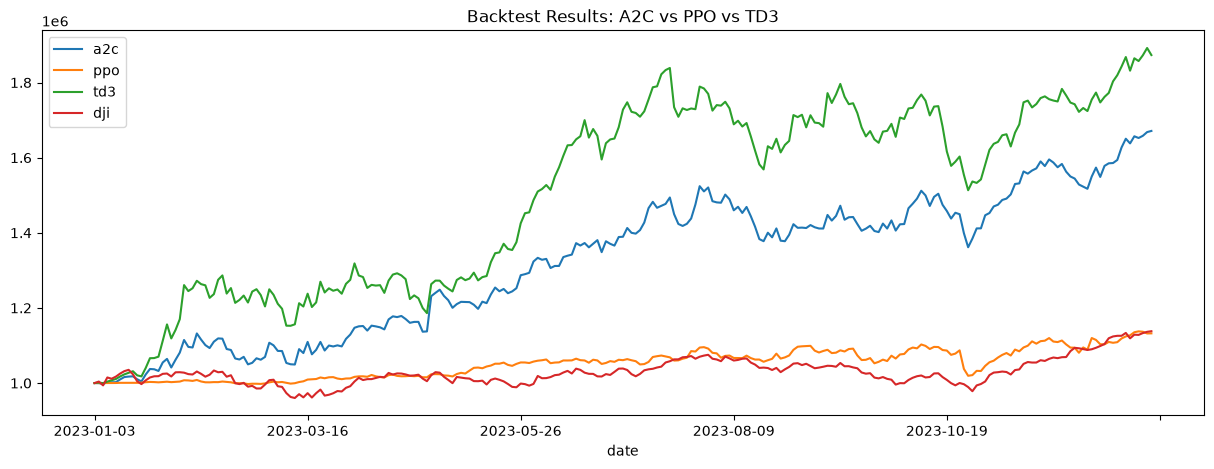

In [48]:
%matplotlib inline
plt.rcParams["figure.figsize"] = (15,5)
plt.figure();
result.plot(title="Backtest Results: A2C vs PPO vs TD3");


#### Cumulative Return and Sharpe Ratio Metrics


In [49]:
import numpy as np
import pandas as pd

def backtest_stats(account_value, value_col_name='account_value'):
    daily_return = account_value[value_col_name].pct_change(1).dropna()

    cum_return = account_value[value_col_name].iloc[-1] / account_value[value_col_name].iloc[0] - 1
    annual_volatility = np.std(daily_return) * np.sqrt(252)
    sharpe_ratio = np.mean(daily_return) / np.std(daily_return) * np.sqrt(252)

    cumulative = (1 + daily_return).cumprod()
    peak = cumulative.cummax()
    drawdown = (cumulative - peak) / peak
    max_drawdown = drawdown.min()

    stats = {
        'Cumulative Return': cum_return,
        'Annual Volatility': annual_volatility,
        'Sharpe Ratio': sharpe_ratio,
        'Max Drawdown': max_drawdown
    }

    return pd.Series(stats)


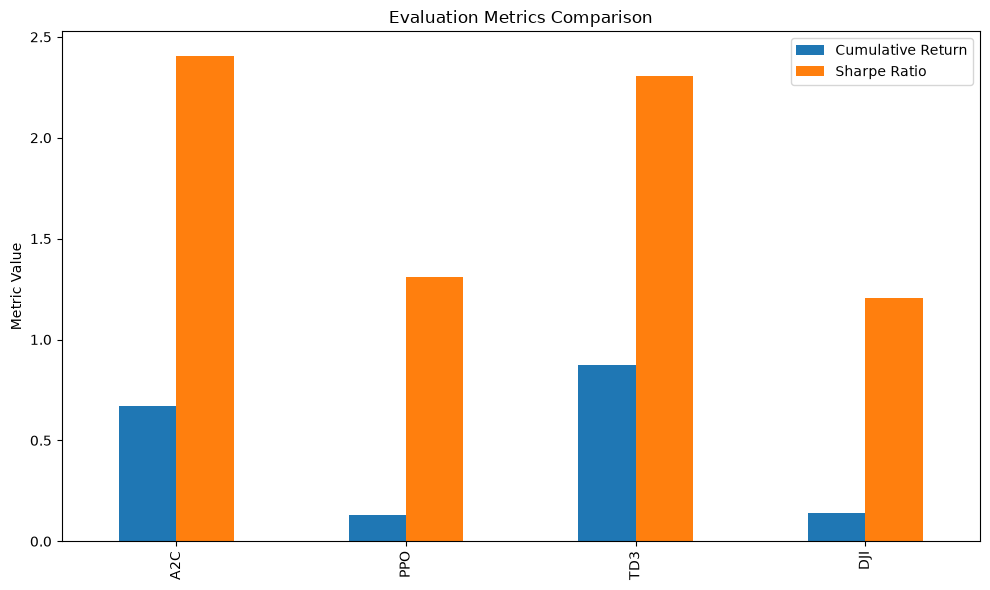

In [50]:
import matplotlib.pyplot as plt
import numpy as np

stats_a2c = backtest_stats(df_account_value_a2c)
stats_ppo = backtest_stats(df_account_value_ppo)
stats_td3 = backtest_stats(df_account_value_td3)
stats_dji = backtest_stats(df_dji)  #  df_dji with  'account_value' coumn added


metrics_df = pd.DataFrame({
    "A2C": stats_a2c,
    "PPO": stats_ppo,
    "TD3": stats_td3,
    "DJI": stats_dji
})

top_metrics = ["Cumulative Return", "Sharpe Ratio"]
metrics_df_filtered = metrics_df.loc[top_metrics]

# Transpose to have models on x-axis
plot_df = metrics_df_filtered.T

# Plot and store axis object
ax = plot_df.plot(kind='bar', figsize=(10, 6))
plt.title("Evaluation Metrics Comparison")
plt.ylabel("Metric Value")

plt.tight_layout()
plt.show()


In [51]:
from IPython.display import display

# Round the values for better presentation
display(metrics_df_filtered.T.round(3))

plt.savefig("evaluation_metrics_comparison.png", dpi=300)
metrics_df_filtered.T.to_csv("evaluation_metrics_table.csv")



,Cumulative Return,Sharpe Ratio
A2C,0.671,2.407
PPO,0.132,1.308
TD3,0.873,2.305
DJI,0.138,1.207


<Figure size 1500x500 with 0 Axes>